Imports and PATH definitions necessary to run the Notebook. It's mandatory to run these 3 cells to install and import the libraries necessary for the rest of the other cells.


In [2]:
#for NLTK stopwords
!python -m nltk.downloader stopwords

<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading package stopwords to /home/zink/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
#all required packages
!pip install -r requirements.txt

In [4]:
import os
import string
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, adjusted_rand_score
)
from sklearn.feature_extraction.text import TfidfVectorizer
from numpy import argmax

from nltk.corpus import stopwords

from lime.lime_text import LimeTextExplainer
from lime import lime_text

import sklearn.cluster as clustering
from transformers import pipeline
VEC_PATH = 'tfidf_vectorizer.joblib'
TRAIN_CLEANED_PATH = 'Data_Set/train_cleaned.csv'
TEST_CLEANED_PATH = 'Data_Set/test_cleaned.csv'
VALIDATION_CLEANED_PATH = 'Data_Set/val_cleaned.csv'

TRAIN_NOT_CLEANED_PATH = 'Data_Set/train_non_cleaned.csv'
TEST_NOT_CLEANED_PATH = 'Data_Set/test_non_cleaned.csv'
VALIDATION_NOT_CLEANED_PATH = 'Data_Set/val_non_cleaned.csv'

RESULTS_DIR = 'cv_results'

/home/zink/Desktop/Pdf das cadeiras/3ºano/Apre/ApreProj/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


"Optional" <br>
We already loaded the data ,cleaned it and saved as a CSV file.
However you can run the following snippets of code to load and clean the data. The snippet with the exercices will allways use whats saved inside the Data_Set folder 

In [27]:


# Load the training data
df_train = pd.read_csv('Data_Set/train.csv', header=0)
df_train = df_train.reset_index()  # make sure indexes pair with number of rows


# Load the test data
df_test = pd.read_csv('Data_Set/test.csv', header=0)
df_test = df_test.reset_index()  # make sure indexes pair with number of rows

# Load the validation data
df_val = pd.read_csv('Data_Set/val.csv', header=0)
df_val = df_val.reset_index()  # make sure indexes pair with number of rows

"Optional": <br>
We are going to clean the data and keep a data frame untouched and his cleaned version respectively

In [3]:

#We found out that some texts are just "none" or an error string, so we remove them here
error_string = "service unavailable request due to maintenance downtime or capacity problems please try again later additionally service unavailable error was encountered while trying to use an errordocument to handle the request"

def clean_data(text,stops):
    text = text.lower()
    trans_table = str.maketrans({p: " " for p in string.punctuation})
    text = text.translate(trans_table)
    words = text.split()
    final = []
    #filter stopwords and words with digits
    final = [word for word in words if word not in stops and not any(char.isdigit() for char in word)]
    cleaned = " ".join(final)
    
    cleaned = " ".join(cleaned.split())  # normalize spaces
    return cleaned

"""
Clean the dataframe by removing stopwords, punctuation, digits and rows with "none" or error string
We create a new dataframe to avoid issues with iterrows and None values
We also create the non-cleaned dataframe to use later for KNN explanations (butt with the "none" and error rows removed)
"""
def clean_dataframe(df):
    
    #WARNINGS - base weekdays will not remove the word "feira" if it appears alone
    base_weekdays = [
        "segunda-feira", "segundafeira", "segunda", "terça-feira", "terçafeira", "terça", "quarta-feira", "quartafeira", 
        "quarta", "quinta-feira", "quintafeira", "quinta", "sexta-feira",
        "sextafeira", "sexta", "sábado", "domingo"
    ]
    meses_pt = [
        "janeiro",
        "fevereiro",
        "marco",
        "março",    # In case accents are used
        "abril",
        "maio",
        "junho",
        "julho",
        "agosto",
        "setembro",
        "outubro",
        "novembro",
        "dezembro"
    ]

    stops = stopwords.words("portuguese")
    stops.extend(base_weekdays)
    stops.extend(meses_pt)

    #Creating the new cleaned dataframe and the non-cleaned one
    cleaned_rows = []
    non_cleaned_rows = []
    for _, row in df.iterrows():
        
        cleaned_row= clean_data(row['Text'],stops)
        
        #depois colocar isto antes do cleaned_row = clean_data(row['Text'],stops)
        if cleaned_row == "none" or cleaned_row == error_string:
            continue
        non_cleaned_row = {}
        non_cleaned_row['Label'] = row['Label']
        non_cleaned_row['Text'] = row['Text']
        non_cleaned_rows.append(non_cleaned_row)
        
        new_row = {}
        new_row['Label'] = row['Label']
        new_row['Text'] = cleaned_row
        cleaned_rows.append(new_row)
    

    non_cleaned_df = pd.DataFrame(non_cleaned_rows).reset_index(drop=True)
    cleaned_df = pd.DataFrame(cleaned_rows).reset_index(drop=True)
    return cleaned_df, non_cleaned_df

df_train_cleaned, df_train_non_cleaned = clean_dataframe(df_train)

df_test_cleaned, df_test_non_cleaned = clean_dataframe(df_test)

df_val_cleaned, df_val_non_cleaned = clean_dataframe(df_val)

#Save it to csv files for future use
df_train_cleaned.to_csv(TRAIN_CLEANED_PATH, index=False)
df_test_cleaned.to_csv(TEST_CLEANED_PATH, index=False)
df_val_cleaned.to_csv(VALIDATION_CLEANED_PATH, index=False)

df_train_non_cleaned.to_csv(TRAIN_NOT_CLEANED_PATH, index=False)
df_test_non_cleaned.to_csv(TEST_NOT_CLEANED_PATH, index=False)
df_val_non_cleaned.to_csv(VALIDATION_NOT_CLEANED_PATH, index=False)
    

"Optional": <br> Examples of cleaned and non-cleaned data

In [ ]:

print(df_train_cleaned.at[32875,'Text'])

print(df_train_non_cleaned.at[32875,'Text'])

print(df_train_cleaned.at[32875,'Label'])

"Optional": <br>
Like the cleaning of the data, we will use the vectorizer in the joblib. You can always run this snippet to extract the TF-IDF features described in Exercise 1 a).

In [4]:
vectorizer = TfidfVectorizer( lowercase=True,
                              max_features=5000,
                              max_df = 0.9,
                              min_df= 10,
                              ngram_range= (1,3),
                              stop_words = "english",
                              use_idf=True,
                              smooth_idf=True
                            )

#Create the TF-IDF vectors for training and testing data (using the training data to fit the vectorizer)
training_vectors = vectorizer.fit_transform(df_train_cleaned['Text'])


#transform the vectorizer to a joblib file for future use

joblib.dump(vectorizer, VEC_PATH)

['tfidf_vectorizer.joblib']

The following cells are for the Exercise 1 b).
The models are already saved in the joblibs, but you can allways run theses cells to see for yourself (it does take a little bit of time). 


In [14]:



#We will use the vectorizer from the joblib file to create the TF-IDF vectors for the test data
vectorizer = joblib.load(VEC_PATH)
df_train_cleaned = pd.read_csv(TRAIN_CLEANED_PATH, header=0)
#vectorizer is already fitted with the training data, so we just transform the test data
X = vectorizer.transform(df_train_cleaned['Text'])
y = df_train_cleaned['Label'].values  

#defining cross-validation 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = 'f1_macro'
RESULTS_DIR = 'cv_results'
os.makedirs(RESULTS_DIR, exist_ok=True)

Here are the models and the HyperParameters that we used.

In [7]:
models = {
    'decision_tree': {
        'pipeline': Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
        'params': {
            'clf__criterion': ['gini', 'entropy'],
            'clf__max_depth': [None, 10, 20],
            'clf__min_samples_leaf': [1, 2, 5]
        }
    },
    'gaussian_nb': {
        # use SVD to reduce dimensionality and produce dense input for GaussianNB
        'pipeline': Pipeline([('svd', TruncatedSVD(n_components=200, random_state=42)),
                              ('clf', GaussianNB())]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__var_smoothing': [1e-9, 1e-8]
        }
    },
    'logreg_l2': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l2', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'logreg_l1': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'mlp': {
        # SVD -> scaler -> MLP
        'pipeline': Pipeline([
            ('svd', TruncatedSVD(n_components=200, random_state=42)),
            ('scaler', StandardScaler()),
            ('clf', MLPClassifier(max_iter=800, random_state=42))
        ]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50)],
            'clf__alpha': [1e-4, 1e-3],
            'clf__learning_rate_init': [1e-3],
            'clf__activation': ['relu']
        }
    }
}

Training the models and Evaluating them using 5-fold cross-validation.
(WARNING: it takes 30 to 40 minutes)

In [ ]:
# We used 5-fold cross-validation with GridSearchCV 
for name, spec in models.items():
    gs = GridSearchCV(spec['pipeline'], spec['params'],
                      cv=cv, scoring=scoring, n_jobs=-1, verbose=0, refit=True)
    gs.fit(X, y)
    
    #save results
    pd.DataFrame(gs.cv_results_).to_csv(os.path.join(RESULTS_DIR, f"{name}_cv_results.csv"), index=False)
    joblib.dump(gs.best_estimator_, os.path.join(RESULTS_DIR, f"{name}_best_estimator.joblib"))
    print(f"Saved cv_results and best_estimator for {name} in {RESULTS_DIR}")

print("\nAll searches complete. Results directory:", RESULTS_DIR)

Saved cv_results and best_estimator for decision_tree in cv_results
Saved cv_results and best_estimator for gaussian_nb in cv_results
Saved cv_results and best_estimator for logreg_l2 in cv_results
Saved cv_results and best_estimator for logreg_l1 in cv_results
Saved cv_results and best_estimator for mlp in cv_results

All searches complete. Results directory: cv_results


"Mandatory":<br>
Auxiliary functions for computing metrics and plotting ROC/AUC (Exercise 1 b) and c) )

In [7]:
#Auxiliary functions for computing metrics and plotting ROC/AUC (Exercise 1 b) and c) )

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
RESULTS_DIR = "cv_results"
OUT_METRICS = os.path.join(RESULTS_DIR, "metrics_comparison.csv")
OUT_ROC = os.path.join(RESULTS_DIR, "best_model_roc.png")

def try_get_scores(est, X, y):
    # attempt predict_proba then decision_function; return None if not available
    try:
        probs = cross_val_predict(est, X, y, cv=CV, method='predict_proba', n_jobs=-1)
        return probs
    except Exception:
        try:
            scores = cross_val_predict(est, X, y, cv=CV, method='decision_function', n_jobs=-1)
            return scores
        except Exception:
            return None
        
def compute_metrics(estimators, X, y):
    rows = []
    scores_cache = {}
    for name, est in estimators.items():
        print(f"Evaluating: {name}")
        y_pred = cross_val_predict(est, X, y, cv=CV, n_jobs=-1)
        acc = accuracy_score(y, y_pred)
        prec = precision_score(y, y_pred, average='macro', zero_division=0)
        rec = recall_score(y, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y, y_pred, average='macro', zero_division=0)
        rows.append({
            'model': name,
            'accuracy': acc,
            'precision_macro': prec,
            'recall_macro': rec,
            'f1_macro': f1
        })
        scores = try_get_scores(est, X, y)
        if scores is not None:
            scores_cache[name] = scores
    dfm = pd.DataFrame(rows).sort_values(by='f1_macro', ascending=False).reset_index(drop=True)
    dfm.to_csv(OUT_METRICS, index=False)
    print(f"\nSaved metrics table to {OUT_METRICS}\n")
    print(dfm.to_string(index=False, float_format="%.4f"))
    return dfm, scores_cache

def plot_roc_for_best(dfm, scores_cache, y):
    best_name = dfm.loc[0, 'model']
    print(f"\nBest model by f1_macro: {best_name}")
    if best_name not in scores_cache:
        print("No probability/score available for best model; cannot plot ROC/AUC.")
        return
    y_score = scores_cache[best_name]
    classes = np.unique(y)
    n_classes = len(classes)
    plt.figure(figsize=(8,6))
    if n_classes == 2:
        # binary: ensure shape and get positive-class scores
        if y_score.ndim == 2 and y_score.shape[1] >= 2:
            prob_pos = y_score[:,1]
        else:
            prob_pos = y_score.ravel()
        fpr, tpr, _ = roc_curve(y, prob_pos, pos_label=classes[-1])
        auc_val = roc_auc_score(y, prob_pos)
        plt.plot(fpr, tpr, label=f'{best_name} (AUC = {auc_val:.4f})', lw=2)
    else:
        # multiclass: one-vs-rest per-class curves + macro AUC
        y_bin = label_binarize(y, classes=classes)
        aucs = []
        for i, cls in enumerate(classes):
            if y_score.ndim == 2 and y_score.shape[1] == n_classes:
                score_i = y_score[:, i]
            else:
                score_i = y_score.ravel()
            fpr, tpr, _ = roc_curve(y_bin[:, i], score_i)
            auc_i = roc_auc_score(y_bin[:, i], score_i)
            aucs.append(auc_i)
            plt.plot(fpr, tpr, lw=1, label=f'class {cls} (AUC={auc_i:.3f})')
        try:
            macro_auc = roc_auc_score(y_bin, y_score, average='macro', multi_class='ovr')
        except Exception:
            macro_auc = np.mean(aucs)
        plt.plot([], [], ' ', label=f'macro AUC = {macro_auc:.4f}')
    
    plt.plot([0,1], [0,1], 'k--', alpha=0.5)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC curve — logreg_l12')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(OUT_ROC)
    print(f"Saved ROC plot to {OUT_ROC}")
    plt.show()


"Mandatory": <br>
We will get the best models saved in the joblibs and show their test metrics and plot the ROC curve for the best model
Exercise 1 b) & c)

In [ ]:
#load all the best models

#in case you did not run the cell with the models dictionary : ) 
models_names = ['decision_tree', 'gaussian_nb', 'logreg_l2', 'logreg_l1', 'mlp']

best_models = {}
for name in models_names:
    model_path = os.path.join(RESULTS_DIR, f"{name}_best_estimator.joblib")
    best_models[name] = joblib.load(model_path)
 
#load the data again
vectorizer = joblib.load(VEC_PATH)
df_train_cleaned = pd.read_csv(TRAIN_CLEANED_PATH, header=0)

X = vectorizer.transform(df_train_cleaned['Text'])
y = df_train_cleaned['Label'].values  

dfm, scores_cache = compute_metrics(best_models, X, y)
plot_roc_for_best(dfm, scores_cache, y)



Evaluating: decision_tree
Evaluating: gaussian_nb
Evaluating: logreg_l2
Evaluating: logreg_l1


"Mandatory":
Exercise 2 a)

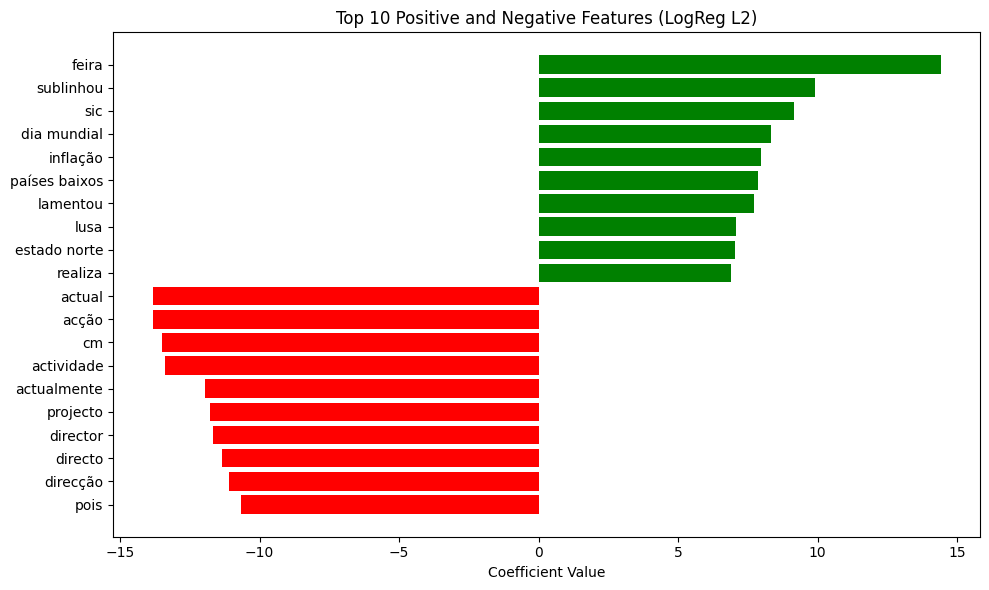

In [5]:
#2 a) 
best_model_path = "cv_results/logreg_l2_best_estimator.joblib" #REMOVER ESTA LINHA SE JA TIVER DEFINIDO ANTES
vectorizer = joblib.load(VEC_PATH)
feature_names = vectorizer.get_feature_names_out()


pipeline = joblib.load(best_model_path)
top_n=10

#Get the models from the pipelines to analyze the coefficients
best_model = pipeline.named_steps['clf']
coefs = best_model.coef_.ravel() #.ravel() para transformar numa array 1D porque a classificaçao é binaria
sorted_idx = np.argsort(coefs)
top_positive_idx = sorted_idx[-top_n:][::-1]
top_negative_idx = sorted_idx[:top_n]

# Prepare data for bar plot
top_features = np.concatenate([top_positive_idx, top_negative_idx])
top_feature_names = [feature_names[i] for i in top_features]
top_feature_coefs = coefs[top_features]

plt.figure(figsize=(10, 6))
colors = ['green'] * top_n + ['red'] * top_n
plt.barh(top_feature_names, top_feature_coefs, color=colors)
plt.xlabel('Coefficient Value')
plt.title(f'Top {top_n} Positive and Negative Features (LogReg L2)')
plt.gca().invert_yaxis()  # Highest at top
plt.tight_layout()
plt.show()

"Mandatory"Exercise 2 b)

In [6]:
#2 b)
model_l2_path = "cv_results/logreg_l2_best_estimator.joblib"
model_l1_path = "cv_results/logreg_l1_best_estimator.joblib"
pipeline_l2 = joblib.load(model_l2_path)
pipeline_l1 = joblib.load(model_l1_path)

#Get the models from the pipelines to analyze the coefficients
model_l2 = pipeline_l2.named_steps['clf']
model_l1 = pipeline_l1.named_steps['clf']
#Colocar na resposta os valores de non-zero features e corrigir esta resposta

def get_nonzero_features(model):
    if not hasattr(model, 'coef_'):
        print("Model does not have coef_ attribute; cannot extract feature importances.")
        return
    coefs = model.coef_.ravel()
    nonzero_count = np.sum(coefs != 0)
    print(f"Number of non-zero features: {nonzero_count}")
    return nonzero_count


#Get number of non-zero features for L2 
get_nonzero_features(model_l2)
#Get number of non-zero features for L1
get_nonzero_features(model_l1)

Number of non-zero features: 5000
Number of non-zero features: 2155


np.int64(2155)

"Mandatory" Exercise c) d)

In [5]:


def explain_with_lime_randomsamples(c, df, num_samples=1000):

    if num_samples == 0:
        return
    
    random_idxs = np.random.choice(len(df), size=num_samples, replace=False)

    correct_classifications = 0
    total_classifications = 0

    for idx in random_idxs:
        if argmax(c.predict_proba([df.loc[idx, 'Text']])) == df.loc[idx, 'Label']:
            correct_classifications += 1
        total_classifications += 1

    accuracy = correct_classifications / total_classifications
    print(f"\nLIME-based classification accuracy over {num_samples} random samples: {accuracy}")

def explain_with_lime(model, vectorizer, df, idxs, num_samples=0):
    


    c = make_pipeline(vectorizer, model)
    class_names = ['fake', 'real']
    
    explainer = LimeTextExplainer(class_names=class_names)
    
    for idx in idxs:
        #este exp é so para mostrar o resultado em as_list
        exp = explainer.explain_instance(df.loc[idx, 'Text'], 
                                         c.predict_proba, 
                                         num_features=10) #number of features to show in explanation, we can change it
        print(f"\nLIME explanation for document index {idx}:")
        print(f"Probabilities of being fake and real: {c.predict_proba([df.loc[idx, 'Text']])}")
        
        print(f"True label: {df.loc[idx, 'Label']}")

        exp.as_list()


    explain_with_lime_randomsamples(c, df ,num_samples)
    
#c)
model_l2_path = "cv_results/logreg_l2_best_estimator.joblib"
model_l2 = joblib.load(model_l2_path)


idxs = [2921, 2437, 5557, 1697]
df_val_cleaned = pd.read_csv('Data_Set/val_cleaned.csv', header=0)
df_val_cleaned = df_val_cleaned.reset_index()  # make sure indexes pair with
explain_with_lime(model_l2, vectorizer, df_val_cleaned, idxs)
#d)
idxs = [2921, 2437, 5557, 1697]
model_mlp_path = "cv_results/mlp_best_estimator.joblib"
model_mlp = joblib.load(model_mlp_path)
explain_with_lime(model_mlp, vectorizer, df_val_cleaned, idxs, num_samples=1000)



LIME explanation for document index 2921:
Probabilities of being fake and real: [[0.00114812 0.99885188]]
True label: 1

LIME explanation for document index 2437:
Probabilities of being fake and real: [[0.9988932 0.0011068]]
True label: 0

LIME explanation for document index 5557:
Probabilities of being fake and real: [[0.00452681 0.99547319]]
True label: 1

LIME explanation for document index 1697:
Probabilities of being fake and real: [[0.84205924 0.15794076]]
True label: 0

LIME explanation for document index 2921:
Probabilities of being fake and real: [[0.00528068 0.99471932]]
True label: 1

LIME explanation for document index 2437:
Probabilities of being fake and real: [[0.86318719 0.13681281]]
True label: 0

LIME explanation for document index 5557:
Probabilities of being fake and real: [[0. 1.]]
True label: 1

LIME explanation for document index 1697:
Probabilities of being fake and real: [[9.99725311e-01 2.74689488e-04]]
True label: 0

LIME-based classification accuracy over 1

"Mandatory" Exercise 3
Note: for Exercise 3 b) it will create a cluster_semantic_labels.txt file with the labels for each cluster. However we print a more detailed version of the results.

Loading zero-shot classification model (this may take a moment)...


Device set to use cuda:0



AUTOMATIC SEMANTIC LABELING USING ZERO-SHOT CLASSIFICATION

CLUSTER 0

Top 10 terms: ucrânia, rússia, russo, guerra, putin, wagner, moscovo, russa, kiev, zelensky

3 Closest documents:

  [1] Doc 22310 (REAL) - Distance: 0.8132
      Preview: líder grupo wagner quer batalha final clarificar situação ucrânia “em teoria rússia pôs fim isto” yevgeny prigojin quer rússia declare cumpridos objet...
      Predicted topic: russia-ukraine conflict news (confidence: 0.19)

  [2] Doc 7742 (REAL) - Distance: 0.8175
      Preview: rússia adormeceu acordou alvoroço rebelião grupo paramilitar wagner controla rostov moscovo alvo prigozhin promete ir fim garante homens renderão puti...
      Predicted topic: entertainment news (confidence: 0.18)

  [3] Doc 15729 (REAL) - Distance: 0.8181
      Preview: compreender conflito podemos esperar contraofensiva ucraniana contraofensiva ucraniana dimensão mau sinal demorar tanto pode fazer parte estratégia uc...
      Predicted topic: political news (confiden

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


      Predicted topic: entertainment news (confidence: 0.37)

  → ASSIGNED LABEL: 'entertainment news (fake)'
  → Topic votes: ['entertainment news', 'entertainment news', 'entertainment news']
  → Cluster size: 6675 documents (5235 fake, 1440 real)

CLUSTER 3

Top 10 terms: euros, milhões, milhões euros, mil, mil milhões, mil euros, ano, banco, valor, mil milhões euros

3 Closest documents:

  [1] Doc 7145 (FAKE) - Distance: 0.8100
      Preview: milhões euros fogem offshores...
      Predicted topic: political news (confidence: 0.18)

  [2] Doc 40477 (REAL) - Distance: 0.8123
      Preview: infraestruturas portugal metropolitano lisboa maiores beneficiários prr total plano recuperação resiliência contabilizam beneficiários projetos metrop...
      Predicted topic: economic news (confidence: 0.16)

  [3] Doc 4527 (REAL) - Distance: 0.8134
      Preview: economia portuguesa passa défice excedente externo milhões regulador afirma aumento exportações reflete sobretudo contributo viagens 

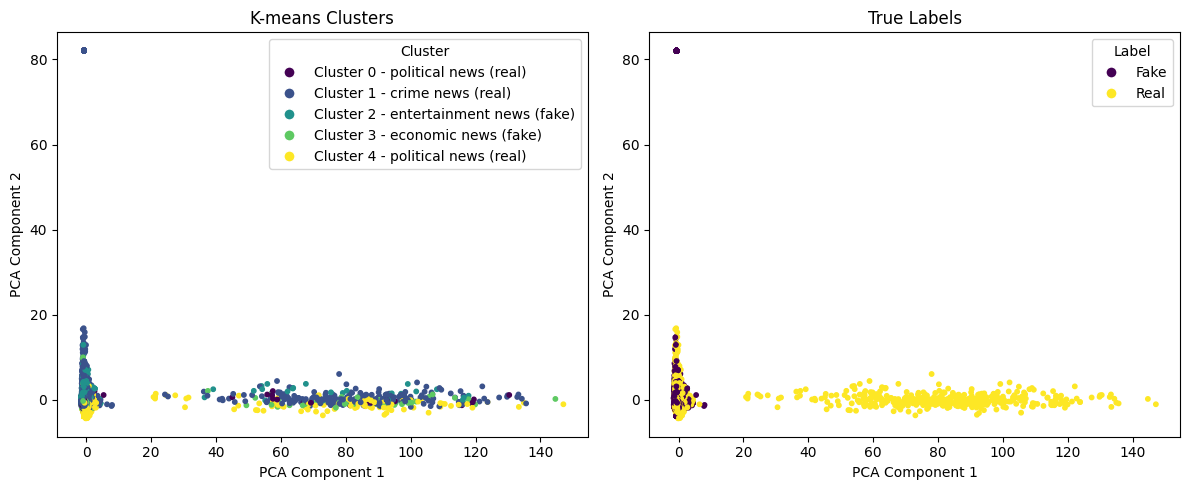

Variance explained by each PCA component: [0.01165893 0.00491687]
Total explained variance: 0.01657580018461578


In [4]:

vectorizer = joblib.load(VEC_PATH)
df_train_cleaned = pd.read_csv(TRAIN_CLEANED_PATH, header=0)
training_vectors = vectorizer.transform(df_train_cleaned['Text'])
terms = vectorizer.get_feature_names_out()

k = 5
n_init = 10 #number of time the k-means algorithm will be run with different centroid seeds

#a) apply k-means to the training data with k=5 clusters
kmeans_model = clustering.KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=n_init)

#apply model to training data
kmeans_model.fit(training_vectors)

order_centroids = kmeans_model.cluster_centers_.argsort()[:, ::-1]

#b) Inspect 3 documents closest to each centroid, and afterwards, assign semantic labels to each cluster 

distances = kmeans_model.transform(training_vectors)

# Load zero-shot classifier for automatic semantic labeling
print("Loading zero-shot classification model (this may take a moment)...")

classifier = pipeline("zero-shot-classification", 
                     model="typeform/distilbert-base-uncased-mnli",
                     device=0)  # use device=0 if you have GPU

# Define candidate topic labels
candidate_labels = ["political news", "health news", "sports news",
                   "entertainment news", "economic news", "crime news",
                   "science news", "general news", "russia-ukraine conflict news"]

# Dictionary to store semantic labels
cluster_labels = {}

print("\n" + "="*80)
print("AUTOMATIC SEMANTIC LABELING USING ZERO-SHOT CLASSIFICATION")
print("="*80)

for i in range(k):
    print(f"\n{'='*80}")
    print(f"CLUSTER {i}")
    print(f"{'='*80}")
    
    # Get top terms for this cluster
    top_terms = [terms[ind] for ind in order_centroids[i, :10]]
    print(f"\nTop 10 terms: {', '.join(top_terms)}")
    
    # Find documents assigned to this cluster
    assigned_idxs = np.where(kmeans_model.labels_ == i)[0]
    
    # Find the 3 closest documents to the centroid
    closest_idxs = assigned_idxs[np.argsort(distances[assigned_idxs, i])[:3]]
    
    print(f"\n3 Closest documents:")
    topic_votes = []
    closest_labels = []
    
    for rank, idx in enumerate(closest_idxs, 1):
        label_str = "REAL" if df_train_cleaned.iloc[idx]['Label'] == 1 else "FAKE"
        closest_labels.append(df_train_cleaned.iloc[idx]['Label'])
        text = df_train_cleaned.iloc[idx]['Text']
        text_preview = text[:150]
        
        print(f"\n  [{rank}] Doc {idx} ({label_str}) - Distance: {distances[idx, i]:.4f}")
        print(f"      Preview: {text_preview}...")
        
        # Classify this document (limit to 512 chars for speed)
        text_for_classification = text[:512]
        result = classifier(text_for_classification, candidate_labels)
        predicted_topic = result['labels'][0]
        confidence = result['scores'][0]
        
        print(f"      Predicted topic: {predicted_topic} (confidence: {confidence:.2f})")
        topic_votes.append(predicted_topic)
    
    # Determine dominant topic by majority vote
    main_topic = max(set(topic_votes), key=topic_votes.count)
    

    
  
    # Show cluster statistics
    cluster_docs = df_train_cleaned.iloc[assigned_idxs]
    n_fake = np.sum(cluster_docs['Label'] == 0)
    n_real = np.sum(cluster_docs['Label'] == 1)

    # Determine if predominantly fake or real
    avg_label = np.mean(n_real / (n_fake + n_real))
    label_type = "real" if avg_label > 0.5 else "fake"
    
    # Create semantic label
    semantic_label = f"{main_topic} ({label_type})"
    cluster_labels[i] = semantic_label
    total = len(cluster_docs)

    print(f"\n  → ASSIGNED LABEL: '{semantic_label}'")
    print(f"  → Topic votes: {topic_votes}")
    print(f"  → Cluster size: {total} documents ({n_fake} fake, {n_real} real)")

print("\n" + "="*80)
print("FINAL CLUSTER LABELS")
print("="*80)
for cluster_id, label in cluster_labels.items():
    cluster_size = np.sum(kmeans_model.labels_ == cluster_id)
    print(f"Cluster {cluster_id}: '{label}' ({cluster_size} documents)")

# Save labels to file
with open("cluster_semantic_labels.txt", "w", encoding="utf-8") as f:
    f.write("CLUSTER SEMANTIC LABELS (Zero-Shot Classification)\n")
    f.write("="*80 + "\n\n")
    for cluster_id, label in cluster_labels.items():
        cluster_size = np.sum(kmeans_model.labels_ == cluster_id)
        f.write(f"Cluster {cluster_id}: {label} ({cluster_size} documents)\n")

print("\nCluster labels saved to 'cluster_semantic_labels.txt'")

#c) Visualize clusters in 2D using PCA. Create two plots: one colored by cluster assignment, one by true label.

X = training_vectors.toarray()
y = df_train_cleaned['Label'].values

#Standardize the data before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(12, 5))
# K-means Clusters subplot
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', s=10)
plt.title('K-means Clusters')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
# Add legend for clusters
handles1 = [plt.Line2D([0], [0], marker='o', color='w',
                       markerfacecolor=scatter1.cmap(scatter1.norm(i)), markersize=8, label=f'Cluster {i} - {cluster_labels[i]}')
            for i in range(kmeans_model.n_clusters)]
plt.legend(handles=handles1, title="Cluster", loc='best')

# True Labels subplot
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_train_cleaned['Label'], cmap='viridis', s=10)
plt.title('True Labels')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
# Add legend for true labels
handles2 = [plt.Line2D([0], [0], marker='o', color='w',
                       markerfacecolor=scatter2.cmap(scatter2.norm(i)), markersize=8,
                       label='Fake' if i == 0 else 'Real') for i in [0, 1]]
plt.legend(handles=handles2, title="Label", loc='best')

plt.tight_layout()
plt.show()

print("Variance explained by each PCA component:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Aqui ficarao por ordem os snippets que fizemos para debbug

In [5]:

    #Debugging functions for TF-IDF matrices

def print_tfidf_summary(vectors):
    n_docs, n_feats = vectors.shape
    nnz = vectors.nnz
    density = nnz / (n_docs * n_feats)
    print(f"shape: {n_docs} x {n_feats}")
    print(f"non-zeros: {nnz}  density: {density:.4%}")

def top_features_for_doc(vectors, feature_names, doc_idx=0, top_n=10):
    row = vectors.getrow(doc_idx).tocoo()
    if row.nnz == 0:
        print(f"doc {doc_idx}: no non-zero features")
        return
    idx = np.argsort(row.data)[::-1][:top_n]
    terms = [feature_names[row.col[i]] for i in idx]
    scores = row.data[idx]
    print(f"Top {top_n} features for doc {doc_idx}:")
    for t, s in zip(terms, scores):
        print(f"  {t}: {s:.4f}")

def top_features_global(vectors, feature_names, top_n=30, by="mean"):
    # by="mean" or "sum"
    if by == "mean":
        vals = np.asarray(vectors.mean(axis=0)).ravel()
    else:
        vals = np.asarray(vectors.sum(axis=0)).ravel()
    top_idx = np.argsort(vals)[::-1][:top_n]
    print(f"Top {top_n} features by {by}:")
    for i in top_idx:
        print(f"  {feature_names[i]}: {vals[i]:.6f}")

def as_dataframe(vectors, feature_names, max_cells=1e9):
    # Convert only if not too large
    n_docs, n_feats = vectors.shape
    if n_docs * n_feats > max_cells:
        raise MemoryError("matrix too large to convert to dense DataFrame")
    return pd.DataFrame(vectors.toarray(), columns=feature_names)


In [7]:
# usage examples Debugging

feature_names = vectorizer.get_feature_names_out()

print_tfidf_summary(training_vectors)
top_features_for_doc(training_vectors, feature_names, doc_idx=0, top_n=15)
top_features_global(training_vectors, feature_names, top_n=40, by="mean")

shape: 50549 x 5000
non-zeros: 5084304  density: 2.0116%
Top 15 features for doc 0:
  operação: 0.3811
  pj: 0.3435
  droga: 0.2627
  movimentos: 0.2609
  tráfico: 0.2445
  iii: 0.1928
  inspeção: 0.1808
  realizadas: 0.1662
  busca: 0.1613
  feitas: 0.1414
  ações: 0.1409
  combate: 0.1327
  oito: 0.1269
  internacional: 0.1177
  comunicado: 0.1076
Top 40 features by mean:
  anos: 0.021404
  euros: 0.020677
  portugal: 0.017591
  milhões: 0.016831
  governo: 0.016404
  pessoas: 0.016116
  ter: 0.015616
  ainda: 0.014955
  sobre: 0.014858
  presidente: 0.014729
  feira: 0.014367
  mil: 0.013487
  ano: 0.013455
  dia: 0.013241
  estado: 0.013176
  vai: 0.012976
  ministro: 0.012778
  país: 0.012527
  saúde: 0.012422
  todos: 0.011936
  pode: 0.011721
  costa: 0.011671
  disse: 0.011038
  milhões euros: 0.011009
  lisboa: 0.011002
  segundo: 0.010818
  fazer: 0.010561
  primeiro: 0.010548
  dois: 0.010402
  onde: 0.010334
  porque: 0.010272
  contra: 0.010197
  vida: 0.010044
  agora: 0.

In [ ]:
#Debugging
# --- Corpus-level term summary and prints ---
# compute sums, means and document frequencies for each feature
sums = np.asarray(training_vectors.sum(axis=0)).ravel()
means = np.asarray(training_vectors.mean(axis=0)).ravel()
df_counts = np.diff(training_vectors.tocsc().indptr)  # documents-per-term

summary = pd.DataFrame({
    'term': feature_names,
    'sum': sums,
    'mean': means,
    'df': df_counts
})
if hasattr(vectorizer, 'idf_'):
    summary['idf'] = vectorizer.idf_

# print top terms by different metrics
def print_top_terms(summary, by='sum', top_n=30):
    print(f"\nTop {top_n} terms by {by}:")
    top = summary.sort_values(by=by, ascending=False).head(top_n)
    print(top[['term', 'sum', 'mean', 'df'] + (['idf'] if 'idf' in top.columns else [])].to_string(index=False))

In [ ]:
#DEBUGGING show top terms
print_top_terms(summary, by='sum', top_n=30)
print_top_terms(summary, by='df', top_n=30)

# show sample cleaned texts for first 5 documents
#print('\nSample cleaned texts (first 5 rows):')
#for i in range(min(5, len(df_train))):
    #print(f"[{i}] ", df_train['Text'].iloc[i])

In [ ]:
# save summary CSV DEBUGGING
summary_out = 'tfidf_term_summary.csv'
summary.sort_values(by='sum', ascending=False).to_csv(summary_out, index=False)
print(f"\nSaved term summary to: {summary_out}")

In [ ]:


RESULTS_DIR = "cv_results"
# COLOCAR AQUI O CVS DE VALIDACAO
DATA_CSV = "Data_Set/val.csv"
X_SPARSE_PATH = os.path.join(RESULTS_DIR, "X_sparse.joblib")
VEC_PATH = "tfidf_vectorizer.joblib"
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
OUT_METRICS = os.path.join(RESULTS_DIR, "metrics_comparison.csv")

def load_features(texts):
    """
    texts: pd.Series or list-like of texts for which we need features.
    If a saved X_sparse.joblib exists, reuse it only if row counts match.
    Otherwise transform texts with the saved vectorizer (VEC_PATH).
    """
    if os.path.exists(X_SPARSE_PATH):
        X = joblib.load(X_SPARSE_PATH)
        if X.shape[0] == len(texts):
            print(f"Loaded X sparse from {X_SPARSE_PATH} (rows match: {X.shape[0]})")
            return X
        else:
            print(f"Saved X_sparse has {X.shape[0]} rows but {len(texts)} requested — rebuilding from vectorizer.")
    if os.path.exists(VEC_PATH):
        vec = joblib.load(VEC_PATH)
        X = vec.transform(pd.Series(texts).fillna('').astype(str))
        print(f"Transformed texts with loaded vectorizer {VEC_PATH}")
        return X
    raise FileNotFoundError("No X_sparse.joblib or tfidf_vectorizer.joblib found; run cv_search first.")

def load_data():
    df = pd.read_csv(DATA_CSV)
    if 'Label' not in df.columns:
        raise RuntimeError("CSV must contain 'Label' column")
    y = df['Label'].values
    return df, y

def load_estimators():
    files = [f for f in os.listdir(RESULTS_DIR) if f.endswith("_best_estimator.joblib")]
    files.sort()
    if not files:
        raise RuntimeError(f"No *_best_estimator.joblib files found in {RESULTS_DIR}")
    estimators = {}
    for f in files:
        name = f.replace("_best_estimator.joblib", "")
        estimators[name] = joblib.load(os.path.join(RESULTS_DIR, f))
    return estimators

    